# Inferences About the Linear Correlation Coefficient
---

## Experiment: calculate Pearson correlation and check its invariances.

In [1]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(118)
x = rng.normal(size=80)
y = 0.6 * x + np.sqrt(1 - 0.6**2) * rng.normal(size=x.size)
s_xx = np.sum((x - x.mean())**2)
s_yy = np.sum((y - y.mean())**2)
s_xy = np.sum((x - x.mean()) * (y - y.mean()))
r_manual = s_xy / np.sqrt(s_xx * s_yy)
r_scipy = stats.pearsonr(x, y).statistic
print(f"Manual r={r_manual:.6f}; SciPy r={r_scipy:.6f}")
print("After positive rescaling:", stats.pearsonr(5 + 3*x, -4 + 2*y).statistic)
print("After reversing y:", stats.pearsonr(x, -y).statistic)
print("Theoretical correlation in the generator: 0.6")

Manual r=0.549819; SciPy r=0.549819
After positive rescaling: 0.5498187742149103
After reversing y: -0.5498187742149101
Theoretical correlation in the generator: 0.6


## Experiment: visualize nonlinear dependence with small Pearson correlation.

Pearson r and p: PearsonRResult(statistic=0.0007060219663954093, pvalue=0.9929080065790888)
Spearman rho and p: SignificanceResult(statistic=-0.0006441223832528182, pvalue=0.9935297739852986)


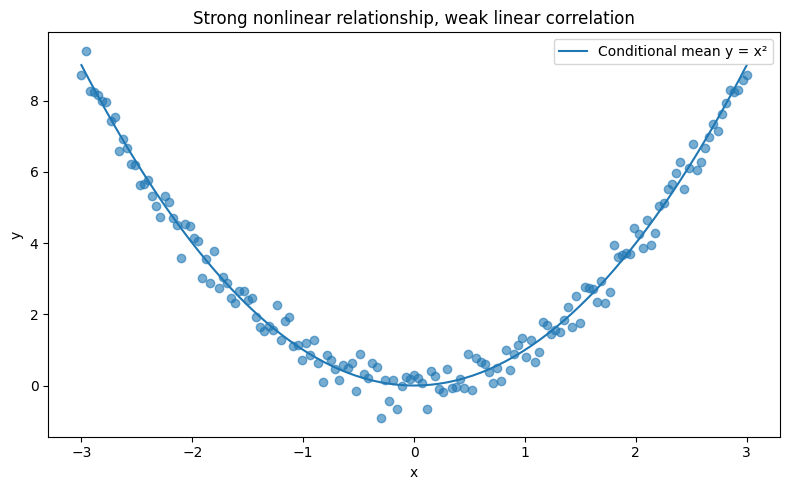

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

rng = np.random.default_rng(119)
x = np.linspace(-3, 3, 161)
y = x**2 + rng.normal(0, 0.35, size=x.size)
print("Pearson r and p:", pearsonr(x, y))
print("Spearman rho and p:", spearmanr(x, y))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, alpha=0.6)
ax.plot(x, x**2, label="Conditional mean y = x²")
ax.set(xlabel="x", ylabel="y", title="Strong nonlinear relationship, weak linear correlation")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/corr_nonlinear_dependence.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: compute Pearson p-values, Fisher confidence limits, and a permutation p-value.

In [3]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(120)
n = 65
x = rng.normal(size=n)
y = 0.42 * x + np.sqrt(1 - 0.42**2) * rng.normal(size=n)
r, p = stats.pearsonr(x, y)
t_obs = r * np.sqrt((n - 2) / (1 - r**2))
p_manual = 2 * stats.t.sf(abs(t_obs), n - 2)
z = np.arctanh(r)
half_width = stats.norm.ppf(0.975) / np.sqrt(n - 3)
ci = (np.tanh(z - half_width), np.tanh(z + half_width))

# Randomization is valid for the independence/exchangeability null.
B = 4000
x_c = x - x.mean()
y_c = y - y.mean()
den = np.linalg.norm(x_c) * np.linalg.norm(y_c)
permuted = np.array([np.dot(x_c, rng.permutation(y_c)) / den for _ in range(B)])
p_perm = (1 + np.count_nonzero(np.abs(permuted) >= abs(r))) / (B + 1)

print(f"r={r:.5f}; SciPy p={p:.5g}; t-reference p={p_manual:.5g}")
print("Approximate Fisher 95% CI:", tuple(round(v, 4) for v in ci))
print(f"Permutation p-value (independence null): {p_perm:.5g}")

r=0.45341; SciPy p=0.00014884; t-reference p=0.00014884
Approximate Fisher 95% CI: (0.2356, 0.6279)
Permutation p-value (independence null): 0.00024994


## Experiment: contrast Pearson and Spearman under a nonlinear monotonic relationship.

In [4]:
import numpy as np
from scipy.stats import pearsonr, spearmanr

rng = np.random.default_rng(121)
x = rng.uniform(0, 3, 120)
y = np.exp(x) + rng.normal(0, 0.2, x.size)
print("Pearson:", pearsonr(x, y))
print("Spearman:", spearmanr(x, y))
print("Pearson after nonlinear rescaling of x:", pearsonr(np.exp(x), y))
print("Spearman after strictly increasing rescaling of x:", spearmanr(np.exp(x), y))

Pearson: PearsonRResult(statistic=0.9327964944389663, pvalue=3.943290680378583e-54)
Spearman: SignificanceResult(statistic=0.9960205569831236, pvalue=9.247671211850184e-126)
Pearson after nonlinear rescaling of x: PearsonRResult(statistic=0.9994214955496666, pvalue=3.9334957147125906e-175)
Spearman after strictly increasing rescaling of x: SignificanceResult(statistic=0.9960205569831236, pvalue=9.247671211850184e-126)


## Experiment: demonstrate confounding and sensitivity to a single outlier.

Pooled Pearson r: 0.6989
Within group 0 r: -0.0091
Within group 1 r: -0.0373
Independent-looking sample r: -0.1488
After replacing one pair by (20,20): 0.8105


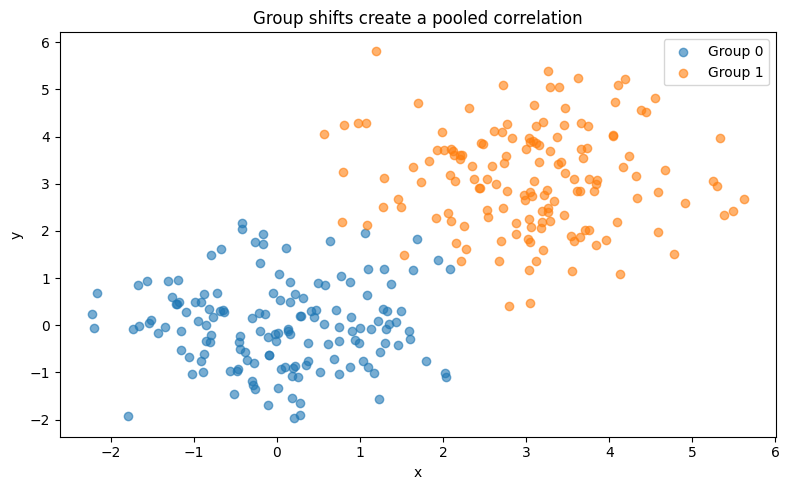

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

rng = np.random.default_rng(122)
n_per_group = 150
group = np.repeat([0, 1], n_per_group)
x = 3 * group + rng.normal(size=group.size)
y = 3 * group + rng.normal(size=group.size)
print("Pooled Pearson r:", round(pearsonr(x, y).statistic, 4))
for g in [0, 1]:
    print(f"Within group {g} r:", round(pearsonr(x[group == g], y[group == g]).statistic, 4))

u = rng.normal(size=80)
v = rng.normal(size=80)
print("Independent-looking sample r:", round(pearsonr(u, v).statistic, 4))
u[-1], v[-1] = 20.0, 20.0
print("After replacing one pair by (20,20):", round(pearsonr(u, v).statistic, 4))

fig, ax = plt.subplots(figsize=(8, 5))
for g in [0, 1]:
    ax.scatter(x[group == g], y[group == g], alpha=0.6, label=f"Group {g}")
ax.set(xlabel="x", ylabel="y", title="Group shifts create a pooled correlation")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/corr_confounding_groups.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: analyze students' two statistics-exam scores.

In [6]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr

url = "https://userpage.fu-berlin.de/soga/data/raw-data/students.csv"
students = pd.read_csv(url)
pairs = students[["score1", "score2"]].apply(pd.to_numeric, errors="coerce").dropna()
if len(pairs) < 50:
    raise ValueError("Fewer than 50 complete paired exam scores")
sample = pairs.sample(n=50, random_state=9)
x = sample["score1"].to_numpy()
y = sample["score2"].to_numpy()
result = pearsonr(x, y)
rank_result = spearmanr(x, y)
print("Pearson r and two-sided p-value:", result)
print("Approximate 95% Pearson confidence interval:",
      result.confidence_interval(confidence_level=0.95))
print("Spearman rank correlation and p-value:", rank_result)
print("n:", len(sample))

Pearson r and two-sided p-value: PearsonRResult(statistic=0.8738759767952877, pvalue=1.2019492648237161e-16)
Approximate 95% Pearson confidence interval: ConfidenceInterval(low=0.7869461225871096, high=0.9267900101824088)
Spearman rank correlation and p-value: SignificanceResult(statistic=0.8582484147580755, pvalue=1.6502530177339312e-15)
n: 50
